# Model Comparison — ANN and SVR against the tree ensembles

Eight regressors (Linear, Ridge, Random Forest, Extra Trees, Gradient Boosting, XGBoost, **SVR**, **ANN**) plus a predict-the-mean baseline, for `Cu_kPa` and `Phi_deg`.

Every model is scored two ways:

- **Shuffled 5-fold** — the protocol of the original notebooks. Rows from one site land in both the training and the test folds.
- **Unseen site (leave-one-site-out)** — each of the 9 sites is predicted by a model that never saw it. This is the score used to choose the deployed model.

and on two feature sets: **with** and **without** the consolidation results `Mv` / `Cv`.

This notebook only reads results. To regenerate them (about 10 minutes): `python -m training.train`, from the project root.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "training").exists() else ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display

from training import report

report._style()
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## Which model is deployed

In [2]:
for target in ("cu", "phi"):
    meta = report.load(target)["meta"]
    print(f"{meta['target_column']}: {meta['model_name']} [{meta['feature_set']}], "
          f"{meta['rows']} rows from {meta['sites']} sites")
    display(pd.DataFrame(meta["metrics"]).T)

Cu_kPa: Extra Trees [plasticity_chart], 227 rows from 9 sites


,rmse,mae,r2
site_holdout,12.909,9.736,0.367
shuffled_5fold,8.078,5.569,0.752


Phi_deg: XGBoost [minimal], 228 rows from 9 sites


,rmse,mae,r2
site_holdout,3.420,2.616,0.258
shuffled_5fold,1.936,1.324,0.762


## Undrained cohesion — `Cu_kPa`

Models sorted by error on an unseen site (full feature set).

,R2 shuffled,R2 unseen site,RMSE shuffled,RMSE unseen site,MAE shuffled,MAE unseen site
Model,,,,,,
Extra Trees,0.826,0.357,6.764,13.012,4.077,9.818
Random Forest,0.776,0.236,7.685,14.178,4.819,11.153
XGBoost,0.806,0.222,7.154,14.306,4.293,11.496
Gradient Boosting,0.798,0.170,7.293,14.781,4.571,11.943
ANN (MLP),0.732,0.119,8.395,15.226,4.865,11.704
SVR,0.703,0.116,8.840,15.256,5.353,12.353
Mean Baseline,-0.021,-0.181,16.397,17.632,13.699,14.865
Ridge Regression,0.469,-3.063,11.823,32.700,9.102,19.420
Linear Regression,0.465,-6.122,11.864,43.297,9.031,22.601


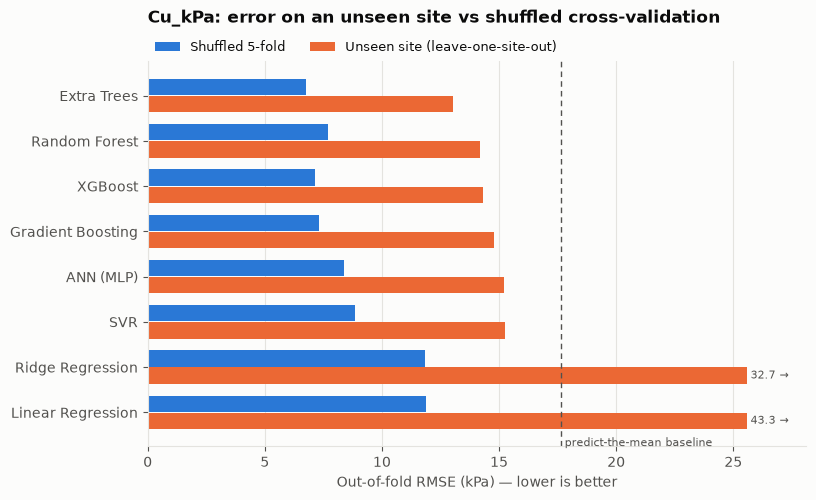

In [3]:
display(report.summary_table("cu"))
report.figure_validation_gap("cu");

,R2 shuffled,R2 unseen site,RMSE shuffled,RMSE unseen site,MAE shuffled,MAE unseen site
Model,,,,,,
Extra Trees,0.740,0.375,8.278,12.826,5.563,9.596
Gradient Boosting,0.719,0.363,8.595,12.952,5.941,10.137
XGBoost,0.761,0.337,7.933,13.208,5.355,10.397
Random Forest,0.721,0.280,8.576,13.770,5.943,10.926
SVR,0.619,0.193,10.020,14.577,6.988,11.755
ANN (MLP),0.708,0.151,8.769,14.953,6.217,11.950
Mean Baseline,-0.021,-0.181,16.397,17.632,13.699,14.865
Ridge Regression,0.358,-1.539,12.997,25.852,10.043,17.485
Linear Regression,0.359,-2.187,12.993,28.965,9.899,17.970


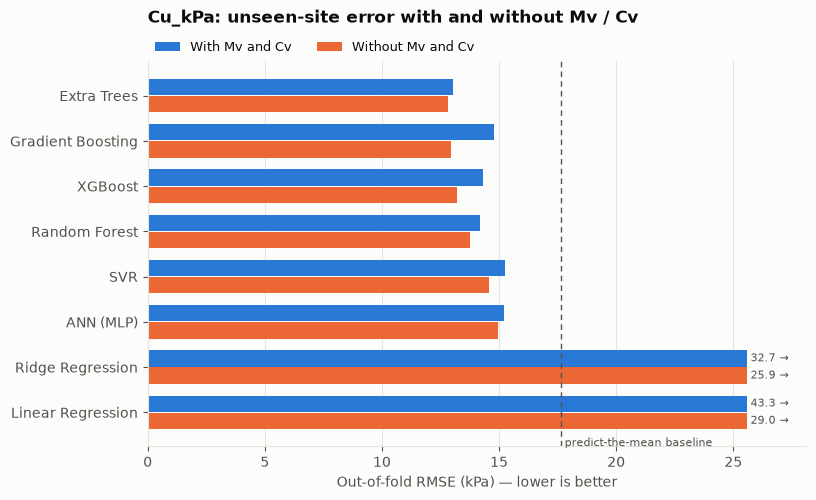

In [4]:
display(report.summary_table("cu", "no_mvcv"))
report.figure_mvcv("cu");

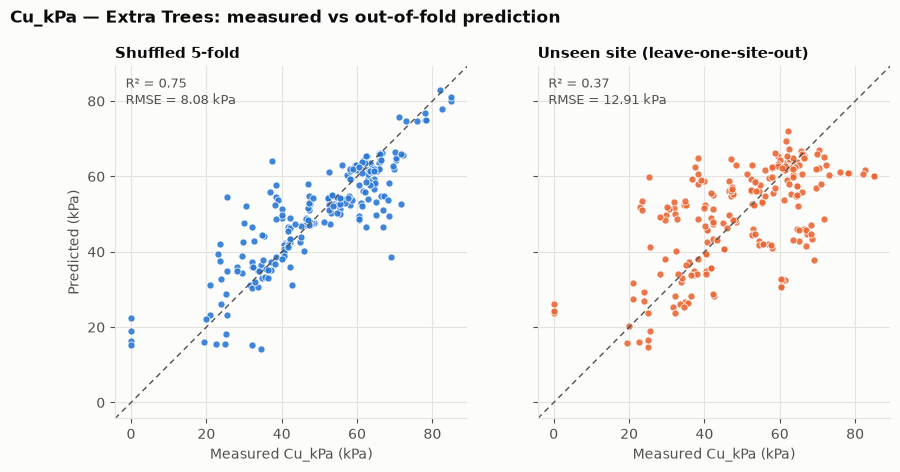

In [5]:
report.figure_parity("cu");

,Site,Rows,Actual_Mean,Predicted_Mean,Bias,RMSE,MAE
0,site_0,5,50.680,50.533,-0.147,1.511,1.377
1,site_1,16,50.688,53.173,2.486,4.180,3.265
2,site_2,27,61.185,60.622,-0.563,8.463,5.890
3,site_3,18,27.011,41.979,14.968,18.323,16.107
4,site_4,43,52.153,57.317,5.164,8.865,6.865
5,site_6,33,64.994,55.540,-9.454,14.537,11.180
6,site_7,41,55.851,43.237,-12.614,16.058,13.318
7,site_8,42,35.402,40.170,4.767,13.232,10.506
8,site_9,2,0.000,25.265,25.265,25.281,25.265


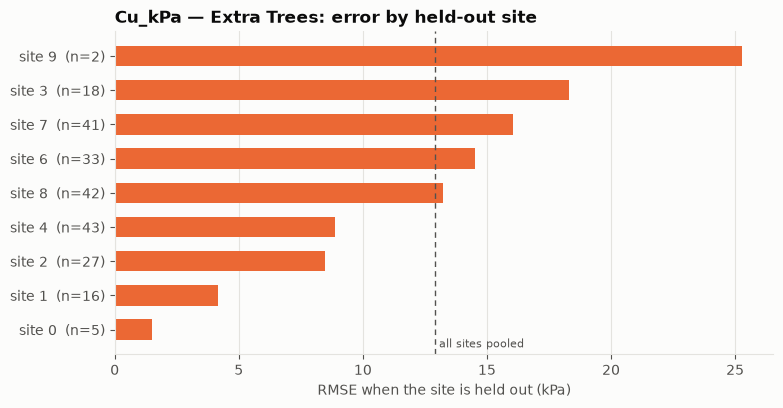

In [6]:
display(report.load("cu")["sites"])
report.figure_site_errors("cu");

Feature importance below is the rise in RMSE (kPa) when a feature is shuffled **in a held-out site**, averaged over sites. Values near zero or negative mean the feature does not help on a new site.

In [7]:
display(report.load("cu")["importance"])

,Feature,Importance,Importance_STD
0,LL,0.496,0.509
1,Sand_Fraction_pct,0.331,1.509
2,A_line_distance,0.172,0.661
3,Sat_Unit_Wt_kN_m3,0.037,0.656
4,Fines_Content_pct,-0.011,0.816
5,PI_calc,-0.297,0.411


## Friction angle — `Phi_deg`

,R2 shuffled,R2 unseen site,RMSE shuffled,RMSE unseen site,MAE shuffled,MAE unseen site
Model,,,,,,
Extra Trees,0.875,0.314,1.403,3.287,0.957,2.675
XGBoost,0.824,0.281,1.665,3.364,1.127,2.669
Random Forest,0.775,0.182,1.883,3.590,1.293,2.846
Gradient Boosting,0.792,0.103,1.811,3.760,1.226,3.054
SVR,0.800,0.072,1.774,3.823,1.298,2.922
Mean Baseline,-0.013,-0.038,3.994,4.043,3.377,3.413
ANN (MLP),0.844,-0.122,1.569,4.204,1.050,3.313
Linear Regression,0.585,-0.347,2.557,4.607,2.005,3.637
Ridge Regression,0.471,-0.578,2.888,4.986,2.328,3.962


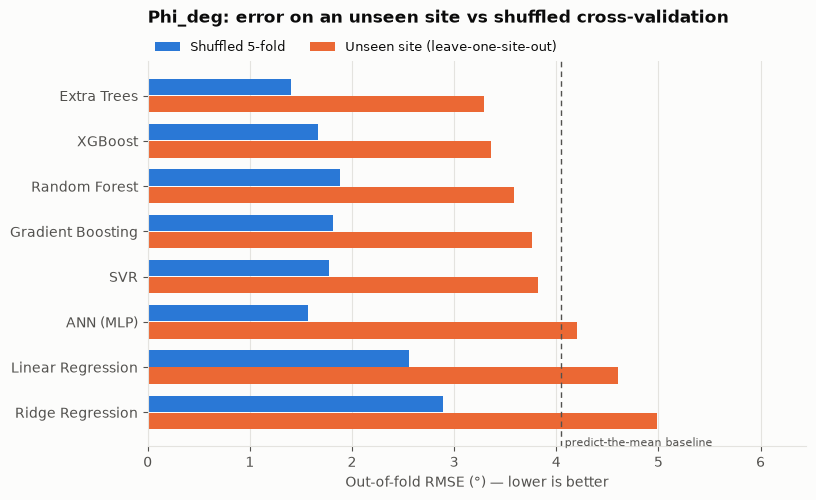

In [8]:
display(report.summary_table("phi"))
report.figure_validation_gap("phi");

,R2 shuffled,R2 unseen site,RMSE shuffled,RMSE unseen site,MAE shuffled,MAE unseen site
Model,,,,,,
XGBoost,0.816,0.317,1.704,3.281,1.170,2.499
Extra Trees,0.827,0.276,1.649,3.378,1.133,2.707
Random Forest,0.774,0.271,1.888,3.388,1.322,2.652
Gradient Boosting,0.762,0.256,1.938,3.424,1.342,2.716
ANN (MLP),0.811,0.089,1.724,3.788,1.172,2.985
SVR,0.703,0.037,2.162,3.895,1.541,3.149
Mean Baseline,-0.013,-0.038,3.994,4.043,3.377,3.413
Linear Regression,0.512,-0.075,2.773,4.116,2.208,3.276
Ridge Regression,0.398,-0.259,3.080,4.454,2.554,3.676


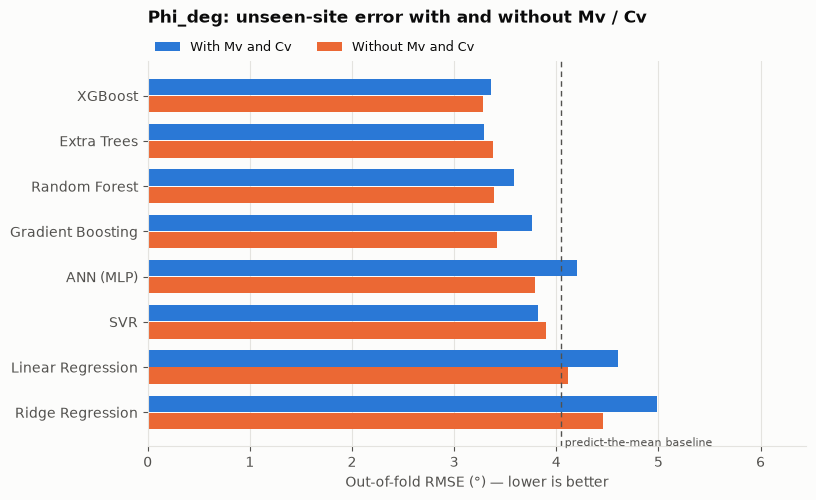

In [9]:
display(report.summary_table("phi", "no_mvcv"))
report.figure_mvcv("phi");

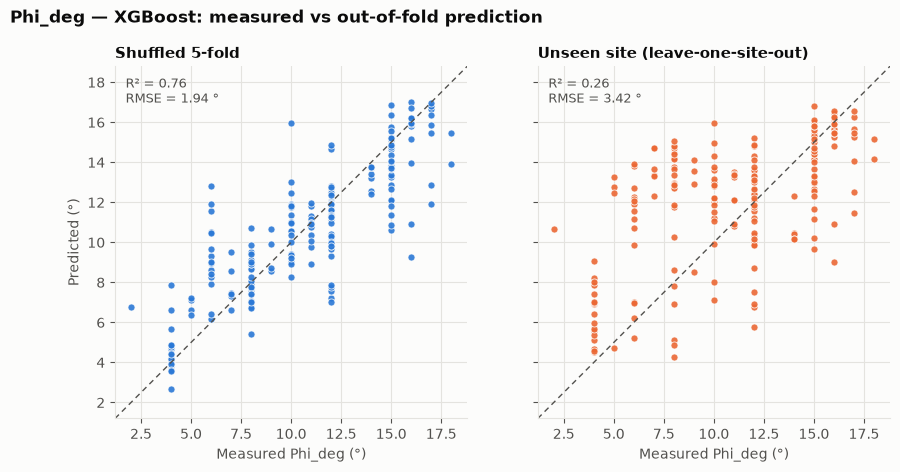

In [10]:
report.figure_parity("phi");

,Site,Rows,Actual_Mean,Predicted_Mean,Bias,RMSE,MAE
0,site_0,5,13.800,13.979,0.179,0.971,0.663
1,site_1,16,14.000,13.305,-0.695,1.206,0.944
2,site_2,27,10.296,12.675,2.379,4.869,4.219
3,site_3,18,10.611,12.820,2.209,3.679,3.259
4,site_4,43,9.047,13.067,4.021,4.746,4.021
5,site_6,34,11.500,9.612,-1.888,3.144,2.521
6,site_7,41,11.390,11.310,-0.081,1.986,1.475
7,site_8,42,9.667,10.985,1.318,2.618,2.031
8,site_9,2,17.000,16.411,-0.589,0.610,0.589


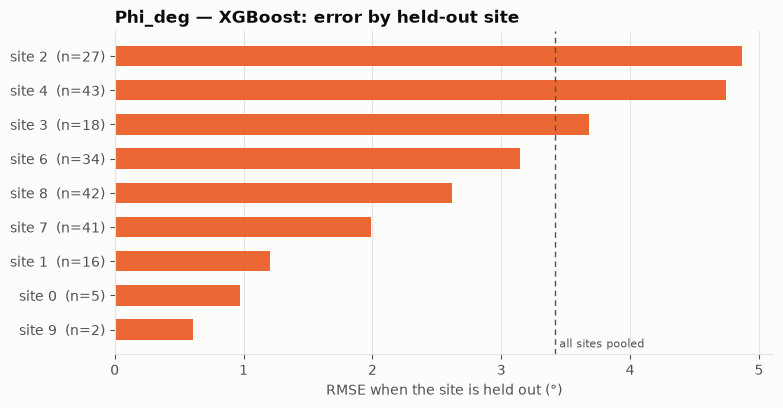

In [11]:
display(report.load("phi")["sites"])
report.figure_site_errors("phi");

In [12]:
display(report.load("phi")["importance"])

,Feature,Importance,Importance_STD
0,Sat_Unit_Wt_kN_m3,0.722,0.722
1,Fines_Content_pct,0.525,0.426
2,PI_calc,0.264,0.293
3,Sand_Fraction_pct,0.032,0.314
4,LL,0.031,0.152


## Hyperparameters chosen for SVR and the ANN

Tuned inside each training fold, so these are the settings picked without sight of the fold being predicted.

In [13]:
for target in ("cu", "phi"):
    log = pd.read_csv(report.OUTPUT_DIR / f"{target}_tuning_log.csv")
    picked = log[(log["Validation"] == "site_holdout") & (log["Feature_Set"] == "full")]
    display(picked.drop(columns=["Validation", "Feature_Set", "Fold"]).set_index(["Model", "Held_Out"]).dropna(axis=1, how="all"))

C  epsilon  gamma  alpha hidden_layer_sizes
Model     Held_Out                                                
SVR       site_0   0.300    0.200  scale    NaN                NaN
          site_1   0.300    0.200  scale    NaN                NaN
          site_2   0.300    0.100   0.01    NaN                NaN
          site_3   0.300    0.050    0.1    NaN                NaN
          site_4   0.300    0.100   0.01    NaN                NaN
          site_6   0.300    0.100   0.01    NaN                NaN
          site_7   3.000    0.200   0.01    NaN                NaN
          site_8   0.300    0.100   0.01    NaN                NaN
          site_9   1.000    0.050  scale    NaN                NaN
ANN (MLP) site_0     NaN      NaN    NaN  1.000           (32, 16)
          site_1     NaN      NaN    NaN  0.100           (32, 16)
          site_2     NaN      NaN    NaN 10.000           (32, 16)
          site_3     NaN      NaN    NaN  1.000              (16,)
          site_4     NaN      NaN    NaN 10.000           (32, 16)
          site_6     NaN      NaN    NaN 10.000            (16, 8)
          site_7     NaN      NaN    NaN 10.000               (8,)
          site_8     NaN      NaN    NaN 10.000            (16, 8)
          site_9     NaN      NaN    NaN  1.000            (16, 8)

C  epsilon  gamma  alpha hidden_layer_sizes
Model     Held_Out                                                 
SVR       site_0    3.000    0.050   0.03    NaN                NaN
          site_1    1.000    0.050  scale    NaN                NaN
          site_2   10.000    0.200   0.03    NaN                NaN
          site_3   10.000    0.200  scale    NaN                NaN
          site_4    0.300    0.050   0.01    NaN                NaN
          site_6    1.000    0.100   0.03    NaN                NaN
          site_7   10.000    0.200   0.01    NaN                NaN
          site_8    1.000    0.050   0.01    NaN                NaN
          site_9    1.000    0.100   0.03    NaN                NaN
ANN (MLP) site_0      NaN      NaN    NaN  1.000            (16, 8)
          site_1      NaN      NaN    NaN  1.000               (8,)
          site_2      NaN      NaN    NaN  1.000            (16, 8)
          site_3      NaN      NaN    NaN 10.000            (16, 8)
          site_4      NaN      NaN    NaN 10.000           (32, 16)
          site_6      NaN      NaN    NaN 10.000            (16, 8)
          site_7      NaN      NaN    NaN 10.000              (16,)
          site_8      NaN      NaN    NaN  0.100           (32, 16)
          site_9      NaN      NaN    NaN  1.000            (16, 8)

## Export figures for the report

Writes high-resolution PNGs to `outputs/figures/`.

In [14]:
report.main()

wrote outputs/figures/cu_validation_gap.png
wrote outputs/figures/cu_mvcv_ablation.png


wrote outputs/figures/cu_parity.png
wrote outputs/figures/cu_site_errors.png
wrote outputs/figures/phi_validation_gap.png


wrote outputs/figures/phi_mvcv_ablation.png
wrote outputs/figures/phi_parity.png


wrote outputs/figures/phi_site_errors.png
